# 05 — Tuning, Benchmark & Operational Decisioning

| Section | What it does |
|---|---|
| 1. Random Forest tuning | Random search, scored on a chronological validation slice |
| 2. XGBoost tuning | Random search with early stopping on the same slice; default vs. tuned |
| 3. Model selection | Pick the operating model on **validation** PR-AUC, never on the test window |
| 4. Benchmark (mean ± std) | Multi-seed results on the test window + forward-chaining CV inside the training window |
| 5. Threshold sweep | Alerts / precision / recall across thresholds |
| 6. Capacity simulation | Fraud captured when investigators review 500 alerts/day |
| 7. Cost-sensitive threshold | Minimize scenario cost: missed fraud \$500, false positive \$10 |
| 8. Alert clustering | K-means on interpretable features only |
| 9. Promotion (off by default) | Replace `app/model.pkl` only if explicitly enabled |

**Protocol.** The test window (last 20% of `TransactionDT`) is used only for reporting. Hyperparameters and the model choice come from the validation slice, which is the last 20% of the training window. Random K-fold CV is not used, because it would mix future transactions into training folds. CV here is forward-chaining: each fold trains on earlier data and validates on the next block of time.

The \$500 / \$10 costs and the 500 alerts/day capacity are **scenario assumptions**, not industry figures. A score means **elevated risk warranting review**, not a determination of fraud.

> **Execution / environment note**
>
> This notebook needs:
>
> - the real IEEE-CIS files `train_transaction.csv` and `train_identity.csv` in `data/raw/`, processed into `data/processed/transactions_features.parquet` (`python src/data_processing.py` and `python src/features.py`, or notebooks 01–02);
> - the packages in `requirements.txt`, in particular **`xgboost`** and **`shap`**;
> - a notebook kernel that runs the project's `.venv` interpreter.
>
> The first code cell **stops with an error** if packages or data are missing, or the data is not the full IEEE-CIS training set. There is no synthetic-data fallback.
>
> **Writes:** only `outputs/xgb_tuning_trials.csv`, `outputs/rf_tuning_trials.csv`, `outputs/tuning_benchmark.csv` and `outputs/alert_clusters.csv`. Existing copies are only replaced if `REPLACE_PREVIOUS_RUN = True`. The main pipeline outputs are never written, and `app/model.pkl` is only replaced if `PROMOTE_TUNED_MODEL = True` (default `False`).
>
> **Runtime:** the fast profile in the guard cell (3 XGBoost trials capped at 300 trees, Random Forest trials reused, 2 seeds, 2 forward-chaining folds) takes tens of minutes on a laptop. Larger settings take hours.

## Environment and data checks

In [1]:
import importlib.util
import sys
from pathlib import Path

REPO = Path("..").resolve()
FEATURES_PATH = REPO / "data" / "processed" / "transactions_features.parquet"
RAW_FILES = [REPO / "data" / "raw" / name for name in ("train_transaction.csv", "train_identity.csv")]

# 1) Required packages: fail loudly, never fall back.
missing = [pkg for pkg in ("xgboost", "shap", "sklearn", "pandas", "pyarrow")
           if importlib.util.find_spec(pkg) is None]
if missing:
    raise ImportError(
        f"Missing packages: {missing}. Install the project requirements into the .venv "
        f"(pip install -r requirements.txt) and select that interpreter as the notebook kernel. "
        f"Current kernel: {sys.executable}"
    )

# 2) Real IEEE-CIS data must be present.
if not FEATURES_PATH.exists():
    absent = [p.name for p in RAW_FILES if not p.exists()]
    hint = (f"Raw files missing from data/raw/: {absent}. Download them from Kaggle "
            "(IEEE-CIS Fraud Detection) after accepting the competition rules." if absent else
            "Raw files found; build the feature table first.")
    raise FileNotFoundError(
        f"{FEATURES_PATH} not found. {hint} Then run, from the repo root: "
        "python src/data_processing.py && python src/features.py"
    )

import xgboost, shap, sklearn
print(f"kernel: {sys.executable}")
print(f"xgboost {xgboost.__version__} | shap {shap.__version__} | scikit-learn {sklearn.__version__}")

kernel: <repo>\.venv\Scripts\python.exe
xgboost 3.4.1 | shap 0.54.1 | scikit-learn 1.9.1


In [2]:
sys.path.insert(0, str(REPO / "src"))

import gc
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import model as m
from features import get_model_feature_columns
from scoring import is_masked_column, label_for_feature

EXPECTED_ROWS, EXPECTED_TRAIN, EXPECTED_TEST = 590_540, 472_432, 118_108

df = pd.read_parquet(FEATURES_PATH)
if len(df) != EXPECTED_ROWS or "isFraud" not in df.columns:
    raise ValueError(
        f"{FEATURES_PATH.name} has {len(df):,} rows; expected the full labeled IEEE-CIS training "
        f"set ({EXPECTED_ROWS:,} rows with isFraud). Rebuild it from the real Kaggle files."
    )

feature_cols = get_model_feature_columns(df, include_masked=True)
cat_cols = [c for c in feature_cols if df[c].dtype.name in ("category", "object")]
CATEGORIES = {c: df[c].astype("category").cat.categories for c in cat_cols}

train, test = m.chronological_split(df)
assert (len(train), len(test)) == (EXPECTED_TRAIN, EXPECTED_TEST), "unexpected split sizes"
del df
gc.collect()

y_train, y_test = train["isFraud"].to_numpy(), test["isFraud"].to_numpy()
print(f"{len(feature_cols)} model features ({len(cat_cols)} categorical) | "
      f"test fraud rate {y_test.mean():.2%}")

Train: 472,432 rows (days 1-141), fraud rate 3.5135%
Test:  118,108 rows (days 141-182), fraud rate 3.4409%
451 model features (31 categorical) | test fraud rate 3.44%


In [3]:
# Output guard: this notebook only ever writes the files below.
OUTPUTS = REPO / "outputs"
PIPELINE_OUTPUTS = {  # produced by src/model.py + src/scoring.py; never written here
    "model_summary.json", "threshold_sweep.csv", "cost_sensitive_threshold.csv",
    "daily_capacity_simulation.csv", "feature_importance.csv", "scored_transactions.csv",
    "shap_summary.png",
}
NOTEBOOK_OUTPUTS = {"xgb_tuning_trials.csv", "rf_tuning_trials.csv", "tuning_benchmark.csv",
                    "alert_clusters.csv"}
REPLACE_PREVIOUS_RUN = False


def save_output(frame: pd.DataFrame, name: str, index: bool = False) -> Path:
    if name in PIPELINE_OUTPUTS:
        raise PermissionError(f"outputs/{name} belongs to the main pipeline; notebook 05 must not write it.")
    if name not in NOTEBOOK_OUTPUTS:
        raise ValueError(f"outputs/{name} is not an output of notebook 05.")
    path = OUTPUTS / name
    if path.exists() and not REPLACE_PREVIOUS_RUN:
        raise FileExistsError(f"{path} already exists. Set REPLACE_PREVIOUS_RUN = True to replace it.")
    frame.to_csv(path, index=index)
    print(f"saved {path}")
    return path


# The deployed model is only replaced when this is switched on explicitly (see the last section).
PROMOTE_TUNED_MODEL = m.PROMOTE_TUNED_MODEL
assert PROMOTE_TUNED_MODEL is False, "PROMOTE_TUNED_MODEL must default to False"

# Run settings: fast profile.
VAL_FRAC = 0.2           # chronological validation slice = last 20% of the training window

# XGBoost: 3 representative combinations, each capped at 300 trees with early stopping
# after 20 rounds without validation improvement. Other parameters keep src/model.py defaults.
XGB_SEARCH_TRIALS = [
    {"learning_rate": 0.08, "max_depth": 6},
    {"learning_rate": 0.12, "max_depth": 4},
    {"learning_rate": 0.15, "max_depth": 6},
]
XGB_SEARCH_N_ESTIMATORS = 300
XGB_EARLY_STOPPING_ROUNDS = 20

# Random Forest: reuse outputs/rf_tuning_trials.csv when it exists (same data, split and
# seed, so re-running the search would reproduce it); otherwise run a small search.
REUSE_RF_TRIALS = True
N_RF_TRIALS = 6
RF_TREES = 300

N_SEEDS = 2              # seeds for the test-window mean +/- std benchmark
N_CV_FOLDS = 2           # forward-chaining folds inside the training window
SEEDS = [m.RANDOM_STATE + i for i in range(N_SEEDS)]
assert REPLACE_PREVIOUS_RUN is False, "REPLACE_PREVIOUS_RUN must default to False"
TRAIN_SPW = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))

## 1. Random Forest: tuning and evaluation

Bagged, decorrelated trees. A strong classical baseline for tabular data, and the natural ensemble to compare with boosting. Inputs: numeric columns as-is (scikit-learn's Random Forest handles missing values natively) and categorical columns as integer codes (−1 = missing). Masked columns are used only as opaque inputs.

To keep the search affordable, each trial trains on a random sample of the fit window (`m.COMPARISON_SAMPLE_SIZE` rows), not the whole window.

With `REUSE_RF_TRIALS = True`, an existing `outputs/rf_tuning_trials.csv` is read back instead of repeating the search. It comes from the same data, split and seed, and the file is not rewritten. The best row's parameters are used for the benchmark.

In [4]:
from sklearn.ensemble import RandomForestClassifier

RF_SEARCH_SPACE = {
    "max_depth": [12, 16, 24, None],
    "min_samples_leaf": [20, 50, 100],
    "max_features": ["sqrt", 0.1, 0.2],
}


def rf_matrix(frame: pd.DataFrame) -> np.ndarray:
    """Numeric columns as float32, categoricals as stable integer codes (-1 = missing)."""
    X = frame[feature_cols].copy()
    for col in cat_cols:
        X[col] = pd.Categorical(X[col], categories=CATEGORIES[col]).codes
    return X.to_numpy(dtype=np.float32)


def make_rf(seed: int = m.RANDOM_STATE, **params) -> RandomForestClassifier:
    return RandomForestClassifier(n_estimators=RF_TREES, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=seed, **params)


fit_part, val_part = m.chronological_split(train, train_frac=1 - VAL_FRAC)
y_val = val_part["isFraud"].to_numpy()
print(f"validation slice: fit on {len(fit_part):,} earlier rows, validate on {len(val_part):,} later rows")

Train: 377,945 rows (days 1-109), fraud rate 3.4119%
Test:  94,487 rows (days 109-141), fraud rate 3.9201%
validation slice: fit on 377,945 earlier rows, validate on 94,487 later rows


In [5]:
def _parse_param(value):
    """Restore a hyperparameter read back from CSV ('None', 'sqrt', '16', '0.2')."""
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        if np.isnan(value):  # pandas reads the text "None" back as NaN
            return None
        return int(value) if float(value).is_integer() else float(value)
    text = str(value).strip()
    if text == "None":
        return None
    for cast in (int, float):
        try:
            return cast(text)
        except ValueError:
            pass
    return text


rf_trials_path = OUTPUTS / "rf_tuning_trials.csv"
if REUSE_RF_TRIALS and rf_trials_path.exists():
    rf_search = pd.read_csv(rf_trials_path).sort_values("val_pr_auc", ascending=False, ignore_index=True)
    missing_cols = [c for c in [*RF_SEARCH_SPACE, "val_pr_auc", "val_roc_auc"] if c not in rf_search]
    if missing_cols:
        raise ValueError(f"{rf_trials_path} lacks columns {missing_cols}; delete it or set REUSE_RF_TRIALS = False.")
    top = rf_search.iloc[0]
    best_rf_params = {k: _parse_param(top[k]) for k in RF_SEARCH_SPACE}
    best_rf = {"params": best_rf_params, "val_pr_auc": float(top["val_pr_auc"]),
               "val_roc_auc": float(top["val_roc_auc"])}
    print(f"reusing {len(rf_search)} Random Forest trials from {rf_trials_path.name} (not rewritten)")
else:
    rf_fit = fit_part.sample(n=min(m.COMPARISON_SAMPLE_SIZE, len(fit_part)), random_state=m.RANDOM_STATE)
    X_rf_fit, y_rf_fit = rf_matrix(rf_fit), rf_fit["isFraud"].to_numpy()
    X_rf_val = rf_matrix(val_part)
    rng = np.random.default_rng(m.RANDOM_STATE)
    rf_trials = []
    for trial in range(N_RF_TRIALS):
        params = {k: v[rng.integers(len(v))] for k, v in RF_SEARCH_SPACE.items()}
        start = time.perf_counter()
        rf = make_rf(**params).fit(X_rf_fit, y_rf_fit)
        metrics = m.score_probabilities(y_val, rf.predict_proba(X_rf_val)[:, 1])
        rf_trials.append({"trial": trial, "params": params, **{k: str(v) for k, v in params.items()},
                          "val_roc_auc": metrics["roc_auc"], "val_pr_auc": metrics["pr_auc"],
                          "fit_seconds": round(time.perf_counter() - start, 1)})
        print(f"RF trial {trial}: val PR-AUC={metrics['pr_auc']:.4f}  {params}")
    rf_search = (pd.DataFrame(rf_trials).drop(columns="params")
                 .sort_values("val_pr_auc", ascending=False, ignore_index=True))
    best_rf = max(rf_trials, key=lambda r: r["val_pr_auc"])
    best_rf_params = best_rf["params"]
    save_output(rf_search, "rf_tuning_trials.csv")

print("best RF params:", best_rf_params, f"| val PR-AUC {best_rf['val_pr_auc']:.4f}")
rf_search.round(4)

reusing 6 Random Forest trials from rf_tuning_trials.csv (not rewritten)
best RF params: {'max_depth': 16, 'min_samples_leaf': 50, 'max_features': 0.2} | val PR-AUC 0.5229


,trial,max_depth,min_samples_leaf,max_features,val_roc_auc,val_pr_auc,fit_seconds
0,1,16.0,50,0.2,0.8995,0.5229,175.4
1,5,NaN,50,sqrt,0.8979,0.5225,52.7
2,3,12.0,50,0.2,0.8953,0.5155,138.7
3,0,12.0,100,0.1,0.8924,0.5106,75.2
4,4,24.0,100,0.2,0.8958,0.5106,191.1
5,2,12.0,100,sqrt,0.8883,0.5007,37.8


## 2. XGBoost: tuning and evaluation

First the **default** parameters from `src/model.py` are scored on the validation slice, as the reference. Then the fast search fits the 3 combinations in `XGB_SEARCH_TRIALS` (learning rate 0.08 / 0.12 / 0.15, depth 6 / 4 / 6). Each is capped at `XGB_SEARCH_N_ESTIMATORS` = 300 trees, with early stopping after `XGB_EARLY_STOPPING_ROUNDS` = 20 rounds without improvement on the same slice. The other parameters keep the `src/model.py` defaults. The best trial's tree count is scaled up for the refit on the full training window (`m.best_params_from_search`).

In [6]:
fit_spw = float((fit_part["isFraud"] == 0).sum() / max((fit_part["isFraud"] == 1).sum(), 1))
default_val_model = m.make_xgb(fit_spw).fit(fit_part[feature_cols], fit_part["isFraud"])
default_val = m.score_probabilities(y_val, default_val_model.predict_proba(val_part[feature_cols])[:, 1])
print(f"XGBoost default params -> val PR-AUC {default_val['pr_auc']:.4f}")
del default_val_model

xgb_rows = []
for trial, combo in enumerate(XGB_SEARCH_TRIALS):
    params = {**m.DEFAULT_XGB_PARAMS, **combo}
    params.pop("n_estimators")
    start = time.perf_counter()
    model = m.make_xgb(fit_spw, n_estimators=XGB_SEARCH_N_ESTIMATORS,
                       early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS, **params)
    model.fit(fit_part[feature_cols], fit_part["isFraud"],
              eval_set=[(val_part[feature_cols], val_part["isFraud"])], verbose=False)
    metrics = m.score_probabilities(y_val, model.predict_proba(val_part[feature_cols])[:, 1])
    xgb_rows.append({"trial": trial, **{k: params[k] for k in m.XGB_SEARCH_SPACE},
                     "best_iteration": int(model.best_iteration),
                     "val_roc_auc": metrics["roc_auc"], "val_pr_auc": metrics["pr_auc"],
                     "fit_seconds": round(time.perf_counter() - start, 1)})
    print(f"XGB trial {trial}: val PR-AUC={metrics['pr_auc']:.4f}  trees={model.best_iteration + 1}  {combo}")
    del model
    gc.collect()

xgb_search = pd.DataFrame(xgb_rows).sort_values("val_pr_auc", ascending=False, ignore_index=True)
best_xgb_params = m.best_params_from_search(xgb_search, val_frac=VAL_FRAC)
save_output(xgb_search, "xgb_tuning_trials.csv")
print("best XGBoost params (refit):", best_xgb_params)
xgb_search.round(4)

XGBoost default params -> val PR-AUC 0.5497


XGB trial 0: val PR-AUC=0.5262  trees=124  {'learning_rate': 0.08, 'max_depth': 6}


XGB trial 1: val PR-AUC=0.5084  trees=122  {'learning_rate': 0.12, 'max_depth': 4}


XGB trial 2: val PR-AUC=0.5384  trees=197  {'learning_rate': 0.15, 'max_depth': 6}
saved <repo>\outputs\xgb_tuning_trials.csv
best XGBoost params (refit): {'max_depth': 6, 'learning_rate': 0.15, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.7, 'reg_lambda': 1.5, 'n_estimators': 246}


,trial,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,best_iteration,val_roc_auc,val_pr_auc,fit_seconds
0,2,6,0.15,3,0.8,0.7,1.5,196,0.8939,0.5384,71.6
1,0,6,0.08,3,0.8,0.7,1.5,123,0.9020,0.5262,55.0
2,1,4,0.12,3,0.8,0.7,1.5,121,0.8951,0.5084,48.3


## 3. Model selection on the validation slice

The operating model is the candidate with the best **validation** PR-AUC. The test window plays no part in this choice. Random Forest validation scores come from a sampled fit window, so they slightly understate what a full-window Random Forest could reach.

In [7]:
validation = pd.DataFrame([
    {"model": "XGBoost (default)", "val_pr_auc": default_val["pr_auc"], "val_roc_auc": default_val["roc_auc"]},
    {"model": "XGBoost (tuned)", "val_pr_auc": xgb_search.loc[0, "val_pr_auc"], "val_roc_auc": xgb_search.loc[0, "val_roc_auc"]},
    {"model": "Random Forest (tuned)", "val_pr_auc": best_rf["val_pr_auc"], "val_roc_auc": best_rf["val_roc_auc"]},
]).sort_values("val_pr_auc", ascending=False, ignore_index=True)
SELECTED = validation.loc[0, "model"]
print(f"selected operating model (by validation PR-AUC): {SELECTED}")
validation.round(4)

selected operating model (by validation PR-AUC): XGBoost (default)


,model,val_pr_auc,val_roc_auc
0,XGBoost (default),0.5497,0.9054
1,XGBoost (tuned),0.5384,0.8939
2,Random Forest (tuned),0.5229,0.8995


## 4. Benchmark: mean ± std

**Multi-seed (test window).** Each candidate is retrained with `N_SEEDS` random seeds on the training window and scored on the test window. Seeds change XGBoost's row and column subsampling and the Random Forest's bootstrap samples. The spread shows how much of a difference between models is just training randomness. Standard deviations use `ddof=1`.

**Forward-chaining CV (training window).** `TimeSeriesSplit` cuts the training window into consecutive blocks. Each fold trains on all earlier blocks and validates on the next one, which shows whether performance is stable across time.

In [8]:
X_rf_train_sample_df = train.sample(n=min(m.COMPARISON_SAMPLE_SIZE, len(train)), random_state=m.RANDOM_STATE)
X_rf_train = rf_matrix(X_rf_train_sample_df)
y_rf_train = X_rf_train_sample_df["isFraud"].to_numpy()
X_rf_test = rf_matrix(test)


def fit_candidate(name: str, seed: int):
    if name == "Random Forest (tuned)":
        return make_rf(seed=seed, **best_rf_params).fit(X_rf_train, y_rf_train)
    if name == "XGBoost (default)":
        clf = m.make_xgb(TRAIN_SPW)
    elif name == "XGBoost (tuned)":
        clf = m.make_xgb(TRAIN_SPW, **best_xgb_params)
    else:
        raise ValueError(f"unknown candidate: {name}")
    clf.set_params(random_state=seed)
    return clf.fit(train[feature_cols], y_train)


def predict_test(name: str, clf) -> np.ndarray:
    X = X_rf_test if name.startswith("Random Forest") else test[feature_cols]
    return clf.predict_proba(X)[:, 1]


CANDIDATES = ["XGBoost (default)", "XGBoost (tuned)", "Random Forest (tuned)"]
seed_rows, test_proba, seed_models = [], {}, {}
for name in CANDIDATES:
    for seed in SEEDS:
        start = time.perf_counter()
        fitted_model = fit_candidate(name, seed)
        proba = predict_test(name, fitted_model)
        metrics = m.score_probabilities(y_test, proba)
        seed_rows.append({"model": name, "seed": seed, **metrics, "fit_seconds": round(time.perf_counter() - start, 1)})
        if seed == m.RANDOM_STATE:  # keep the reference-seed run for the operating analysis
            test_proba[name], seed_models[name] = proba, fitted_model
        print(f"{name:<22} seed {seed}: PR-AUC={metrics['pr_auc']:.4f}  ROC-AUC={metrics['roc_auc']:.4f}")
        gc.collect()

seed_results = pd.DataFrame(seed_rows)
seed_summary = seed_results.groupby("model").agg(
    test_pr_auc_mean=("pr_auc", "mean"), test_pr_auc_std=("pr_auc", "std"),
    test_roc_auc_mean=("roc_auc", "mean"), test_roc_auc_std=("roc_auc", "std"),
    seeds=("seed", "count"),
).reindex(CANDIDATES)
seed_summary.assign(
    **{"PR-AUC (mean ± std)": [f"{a:.4f} ± {b:.4f}" for a, b in zip(seed_summary.test_pr_auc_mean, seed_summary.test_pr_auc_std)],
       "ROC-AUC (mean ± std)": [f"{a:.4f} ± {b:.4f}" for a, b in zip(seed_summary.test_roc_auc_mean, seed_summary.test_roc_auc_std)]}
)[["PR-AUC (mean ± std)", "ROC-AUC (mean ± std)", "seeds"]]

XGBoost (default)      seed 42: PR-AUC=0.4862  ROC-AUC=0.8855


XGBoost (default)      seed 43: PR-AUC=0.4793  ROC-AUC=0.8866


XGBoost (tuned)        seed 42: PR-AUC=0.4955  ROC-AUC=0.8807


XGBoost (tuned)        seed 43: PR-AUC=0.4812  ROC-AUC=0.8799


Random Forest (tuned)  seed 42: PR-AUC=0.4600  ROC-AUC=0.8825


Random Forest (tuned)  seed 43: PR-AUC=0.4586  ROC-AUC=0.8826


,PR-AUC (mean ± std),ROC-AUC (mean ± std),seeds
model,,,
XGBoost (default),0.4827 ± 0.0049,0.8861 ± 0.0008,2
XGBoost (tuned),0.4884 ± 0.0101,0.8803 ± 0.0006,2
Random Forest (tuned),0.4593 ± 0.0010,0.8826 ± 0.0001,2


In [9]:
from sklearn.model_selection import TimeSeriesSplit

cv_rows = []
for fold, (tr_idx, va_idx) in enumerate(TimeSeriesSplit(n_splits=N_CV_FOLDS).split(train)):
    tr, va = train.iloc[tr_idx], train.iloc[va_idx]   # train is already in time order
    y_tr, y_va = tr["isFraud"].to_numpy(), va["isFraud"].to_numpy()
    spw = float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))

    xgb_fold = m.make_xgb(spw, **best_xgb_params).fit(tr[feature_cols], y_tr)
    xgb_metrics = m.score_probabilities(y_va, xgb_fold.predict_proba(va[feature_cols])[:, 1])

    tr_sample = tr.sample(n=min(m.COMPARISON_SAMPLE_SIZE, len(tr)), random_state=m.RANDOM_STATE)
    rf_fold = make_rf(**best_rf_params).fit(rf_matrix(tr_sample), tr_sample["isFraud"].to_numpy())
    rf_metrics = m.score_probabilities(y_va, rf_fold.predict_proba(rf_matrix(va))[:, 1])

    for name, mt in [("XGBoost (tuned)", xgb_metrics), ("Random Forest (tuned)", rf_metrics)]:
        cv_rows.append({"model": name, "fold": fold, "train_rows": len(tr), "val_rows": len(va), **mt})
    print(f"fold {fold}: train {len(tr):,} -> validate {len(va):,} | "
          f"XGB PR-AUC {xgb_metrics['pr_auc']:.4f} | RF PR-AUC {rf_metrics['pr_auc']:.4f}")
    del xgb_fold, rf_fold
    gc.collect()

cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby("model").agg(
    cv_pr_auc_mean=("pr_auc", "mean"), cv_pr_auc_std=("pr_auc", "std"),
    cv_roc_auc_mean=("roc_auc", "mean"), cv_roc_auc_std=("roc_auc", "std"),
)
cv_summary.round(4)

fold 0: train 157,478 -> validate 157,477 | XGB PR-AUC 0.4488 | RF PR-AUC 0.4960


fold 1: train 314,955 -> validate 157,477 | XGB PR-AUC 0.4816 | RF PR-AUC 0.4955


,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std
model,,,,
Random Forest (tuned),0.4957,0.0003,0.8825,0.0080
XGBoost (tuned),0.4652,0.0232,0.8422,0.0302


## 5. Threshold sweep (selected model)

All operating analysis below uses the selected model's reference-seed run (`m.RANDOM_STATE`) on the test window.

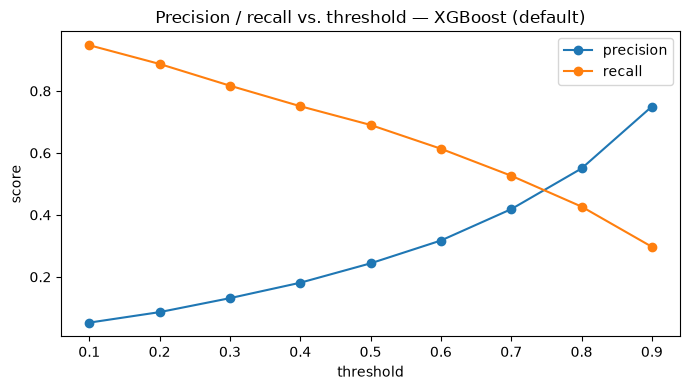

,threshold,alerts,precision,recall,true_positives,false_positives
0,0.1,73675,0.0523,0.9476,3851,69824
1,0.2,41834,0.0862,0.8871,3605,38229
2,0.3,25295,0.1313,0.8169,3320,21975
3,0.4,16852,0.1810,0.7507,3051,13801
4,0.5,11514,0.2436,0.6902,2805,8709
5,0.6,7858,0.3173,0.6134,2493,5365
6,0.7,5111,0.4185,0.5263,2139,2972
7,0.8,3154,0.5498,0.4267,1734,1420
8,0.9,1610,0.7497,0.2970,1207,403


In [10]:
proba = test_proba[SELECTED]
sweep = m.threshold_sweep(y_test, proba)
sweep["threshold"] = sweep["threshold"].round(2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep["threshold"], sweep["precision"], marker="o", label="precision")
ax.plot(sweep["threshold"], sweep["recall"], marker="o", label="recall")
ax.set_xlabel("threshold"); ax.set_ylabel("score"); ax.set_title(f"Precision / recall vs. threshold — {SELECTED}")
ax.legend(); plt.tight_layout(); plt.show()
sweep[["threshold", "alerts", "precision", "recall", "true_positives", "false_positives"]].round(4)

## 6. Fixed capacity: 500 alerts/day

Each test day, investigators review only the `m.DAILY_REVIEW_CAPACITY` highest-scored transactions; fraud below that cut is missed that day. The single global top-500 cut is shown for contrast.

42 test days | average daily fraud capture 78.9% (range 57.1%-95.5%) | average precision 15.3%
single global top-500: precision 93.0%, recall 11.4%


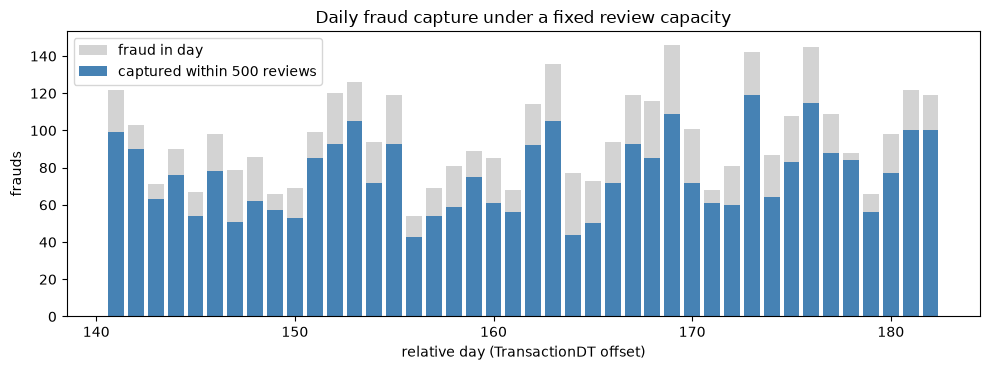

In [11]:
daily = m.daily_capacity_simulation(test, proba, capacity=m.DAILY_REVIEW_CAPACITY)
global_cut = m.capacity_at_k(y_test, proba, k=m.DAILY_REVIEW_CAPACITY)
print(f"{len(daily)} test days | average daily fraud capture {daily['recall'].mean():.1%} "
      f"(range {daily['recall'].min():.1%}-{daily['recall'].max():.1%}) | "
      f"average precision {daily['precision'].mean():.1%}")
print(f"single global top-{global_cut['k']}: precision {global_cut['precision_at_k']:.1%}, "
      f"recall {global_cut['recall_at_k']:.1%}")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(daily["day"], daily["fraud_in_day"], label="fraud in day", color="lightgray")
ax.bar(daily["day"], daily["fraud_captured"], label="captured within 500 reviews", color="steelblue")
ax.set_xlabel("relative day (TransactionDT offset)"); ax.set_ylabel("frauds")
ax.set_title("Daily fraud capture under a fixed review capacity"); ax.legend()
plt.tight_layout(); plt.show()

## 7. Cost-sensitive threshold

Total scenario cost = \$500 × missed frauds + \$10 × false-positive reviews (`m.FALSE_NEGATIVE_COST`, `m.FALSE_POSITIVE_COST`; scenario assumptions). The minimum is compared with the default 0.5 cut-off and with the 0.24 probability threshold from the main pipeline run, which is read from `outputs/model_summary.json` without modifying it.

cost-optimal threshold for XGBoost (default): 0.26 (main pipeline run: 0.24)


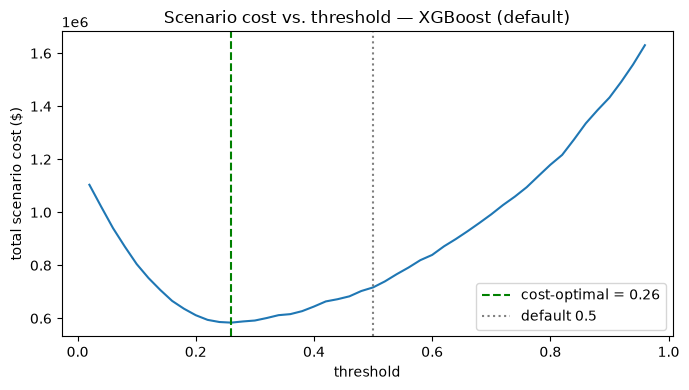

,threshold,alerts,precision,recall,false_negatives,false_positives,total_cost
11,0.24,33811,0.1035,0.8607,566,30313,586130
12,0.26,30621,0.1123,0.8465,624,27181,583810
24,0.50,11514,0.2436,0.6902,1259,8709,716590


In [12]:
cost_curve = m.cost_sensitive_threshold(y_test, proba)
cost_curve["threshold"] = cost_curve["threshold"].round(2)
best_cost = cost_curve.loc[cost_curve["total_cost"].idxmin()]
BEST_THRESHOLD = float(best_cost["threshold"])

pipeline_threshold = json.loads((OUTPUTS / "model_summary.json").read_text())["cost_optimal_threshold"]
reference = cost_curve[cost_curve["threshold"].isin([BEST_THRESHOLD, round(pipeline_threshold, 2), 0.5])]
print(f"cost-optimal threshold for {SELECTED}: {BEST_THRESHOLD:.2f} "
      f"(main pipeline run: {pipeline_threshold:.2f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cost_curve["threshold"], cost_curve["total_cost"])
ax.axvline(BEST_THRESHOLD, color="green", linestyle="--", label=f"cost-optimal = {BEST_THRESHOLD:.2f}")
ax.axvline(0.5, color="gray", linestyle=":", label="default 0.5")
ax.set_xlabel("threshold"); ax.set_ylabel("total scenario cost ($)"); ax.legend()
ax.set_title(f"Scenario cost vs. threshold — {SELECTED}")
plt.tight_layout(); plt.show()
reference[["threshold", "alerts", "precision", "recall", "false_negatives", "false_positives", "total_cost"]].round(4)

### Benchmark table (all candidates, saved to `outputs/tuning_benchmark.csv`)

In [13]:
def operating_profile(name: str) -> dict:
    p = test_proba[name]
    curve = m.cost_sensitive_threshold(y_test, p)
    best = curve.loc[curve["total_cost"].idxmin()]
    day = m.daily_capacity_simulation(test, p, capacity=m.DAILY_REVIEW_CAPACITY)
    metrics = m.score_probabilities(y_test, p)
    return {
        "model": name, "selected": name == SELECTED,
        "val_pr_auc": validation.set_index("model").loc[name, "val_pr_auc"],
        "test_pr_auc_seed_ref": metrics["pr_auc"], "test_roc_auc_seed_ref": metrics["roc_auc"],
        **seed_summary.loc[name, ["test_pr_auc_mean", "test_pr_auc_std", "test_roc_auc_mean", "test_roc_auc_std"]].to_dict(),
        **(cv_summary.loc[name].to_dict() if name in cv_summary.index else {}),
        "cost_optimal_threshold": round(float(best["threshold"]), 2),
        "precision_at_cost_opt": best["precision"], "recall_at_cost_opt": best["recall"],
        "scenario_cost_at_cost_opt": best["total_cost"],
        "avg_daily_recall_at_500": day["recall"].mean(), "avg_daily_precision_at_500": day["precision"].mean(),
    }


benchmark = pd.DataFrame([operating_profile(name) for name in CANDIDATES])
save_output(benchmark, "tuning_benchmark.csv")
benchmark.set_index("model").T

saved <repo>\outputs\tuning_benchmark.csv


model,XGBoost (default),XGBoost (tuned),Random Forest (tuned)
selected,True,False,False
val_pr_auc,0.54972,0.538445,0.522879
test_pr_auc_seed_ref,0.486177,0.495517,0.459973
test_roc_auc_seed_ref,0.885493,0.880694,0.882491
test_pr_auc_mean,0.482734,0.488381,0.459285
test_pr_auc_std,0.004869,0.010091,0.000973
test_roc_auc_mean,0.886053,0.880297,0.882566
test_roc_auc_std,0.000791,0.000562,0.000106
cost_optimal_threshold,0.26,0.22,0.24
precision_at_cost_opt,0.112341,0.121034,0.097052


## 8. Alert clustering (interpretable features only)

Alerts = test transactions at or above the selected model's cost-optimal threshold. K-means runs on `m.CLUSTER_FEATURES` only. The cell below checks that this list contains **no masked column**, so every segment can be described in investigator language. `isFraud` is used only to profile the clusters afterwards, never as an input. The number of clusters k is chosen by (sampled) silhouette score.

30,621 alerts at threshold 0.26


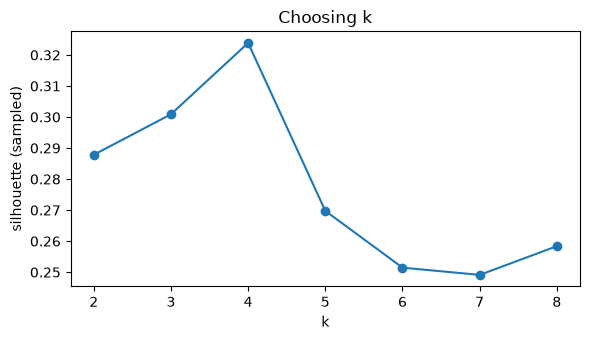

,k,inertia,silhouette
0,2,253105.2972,0.2878
1,3,207396.1873,0.3009
2,4,171689.7698,0.3239
3,5,148385.0304,0.2698
4,6,131392.9653,0.2515
5,7,119052.1385,0.2491
6,8,109948.0058,0.2584


In [14]:
leaked = [c for c in m.CLUSTER_FEATURES if is_masked_column(c)]
assert not leaked, f"masked columns must not be clustering inputs: {leaked}"

alerts = test.loc[proba >= BEST_THRESHOLD].copy()
print(f"{len(alerts):,} alerts at threshold {BEST_THRESHOLD:.2f}")
k_sweep = m.kmeans_k_sweep(m.cluster_matrix(alerts), ks=range(2, 9))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(k_sweep["k"], k_sweep["silhouette"], marker="o")
ax.set_xlabel("k"); ax.set_ylabel("silhouette (sampled)"); ax.set_title("Choosing k")
plt.tight_layout(); plt.show()
k_sweep.round(4)

In [15]:
K = int(k_sweep.loc[k_sweep["silhouette"].idxmax(), "k"])
labels, cluster_profile, _ = m.cluster_alerts(alerts, n_clusters=K)
save_output(cluster_profile.reset_index(), "alert_clusters.csv")
print(f"k = {K}")
cluster_profile.rename(columns=lambda c: label_for_feature(c) if c in m.CLUSTER_FEATURES else c).round(3)

saved <repo>\outputs\alert_clusters.csv
k = 4


,transactions,transaction amount (log-scaled),hour of the relative 24-hour time cycle,hours 0-5 of the relative 24-hour cycle,purchaser uses a free/consumer email domain,identity/device data present,mobile device,this card's prior transaction count,amount vs. this card's typical amount,first transaction seen for this card,time since this card's last transaction,fraud_rate
cluster,,,,,,,,,,,,
0,3219,3.781,12.195,0.339,0.904,1.000,0.994,2148.108,0.917,0.0,252769.088,0.281
2,184,4.739,13.272,0.250,0.832,0.571,0.234,0.000,179.843,1.0,-1.000,0.201
3,5316,4.510,1.633,1.000,0.747,0.226,0.000,2227.688,1.194,0.0,128145.752,0.106
1,21902,4.723,17.507,0.000,0.716,0.133,0.000,2382.324,1.359,0.0,145589.409,0.088


## 9. Promotion of the tuned model (off by default)

`app/model.pkl` is replaced only when **all** of these hold:

1. `PROMOTE_TUNED_MODEL = True` is set in this cell (it defaults to `False`, from `src/model.py`);
2. the selected model is the tuned XGBoost. The app and `src/scoring.py` expect an XGBoost model that takes the feature table directly;
3. the tuned XGBoost beat the default parameters on the **validation** slice.

Saving goes through `m.promote_tuned_model`, which refuses to write while the flag is off. After promoting, `outputs/scored_transactions.csv` and the other pipeline outputs no longer match the deployed model. Re-running `src/scoring.py` to refresh them overwrites those files, so treat it as a separate, deliberate step.

In [16]:
# PROMOTE_TUNED_MODEL = True   # uncomment only to replace app/model.pkl deliberately

tuned_beats_default = xgb_search.loc[0, "val_pr_auc"] > default_val["pr_auc"]
if not PROMOTE_TUNED_MODEL:
    print("PROMOTE_TUNED_MODEL is False: app/model.pkl left unchanged.")
elif SELECTED != "XGBoost (tuned)":
    print(f"Not promoted: the selected model is {SELECTED}, not the tuned XGBoost.")
elif not tuned_beats_default:
    print("Not promoted: tuned XGBoost did not beat the default parameters on validation.")
else:
    logreg_pipe = m.train_baseline_logreg(train, test)[0]
    bundle = m.build_model_bundle(seed_models["XGBoost (tuned)"], logreg_pipe, feature_cols,
                                  BEST_THRESHOLD, xgb_params=best_xgb_params)
    m.promote_tuned_model(bundle, REPO / m.MODEL_PATH, enabled=PROMOTE_TUNED_MODEL)

PROMOTE_TUNED_MODEL is False: app/model.pkl left unchanged.


## Reading the results

Copy results into `REPORT.md` §6 only after a full run on the real data.

- Compare models on the **mean ± std** rows. A gap smaller than about two standard deviations is within seed noise.
- The forward-chaining CV shows whether a model's quality holds across time inside the training window. Fraud patterns drift, so some spread between folds is expected.
- The cost-optimal threshold depends on the \$500 / \$10 scenario. With different costs the threshold moves; re-run section 7 with new `m.FALSE_NEGATIVE_COST` / `m.FALSE_POSITIVE_COST` values to see how.
- Cluster profiles describe alert *segments* in interpretable terms. They are not fraud verdicts, and masked columns play no part in them.